Load the Graph

In [25]:
import pandas as pd

SNAP_URL = "https://snap.stanford.edu/data/soc-sign-bitcoinotc.csv.gz"

df = pd.read_csv(
    SNAP_URL,
    compression="gzip",
    header=None,
    names=["source", "target", "sign", "timestamp"]
)

print(df.head())
print(df.shape)

   source  target  sign     timestamp
0       6       2     4  1.289242e+09
1       6       5     2  1.289242e+09
2       1      15     1  1.289243e+09
3       4       3     7  1.289245e+09
4      13      16     8  1.289254e+09
(35592, 4)


In [26]:
import numpy as np

random_df = df.copy()

def random_signed_weight(original_sign):
    if original_sign > 0:
        # Random positive weight between 0 and 1
        return np.random.uniform(0.0, 1.0)

    elif original_sign < 0:
        # Random negative weight between -1 and 0
        return np.random.uniform(-1.0, 0.0)

    else:
        # Keep zero as zero
        return 0.0

# Apply function to update the 'sign' column
random_df["sign"] = random_df["sign"].apply(random_signed_weight)

# Print a random sample of 5 values to inspect the output
print("Random sample of generated weights:")
print(random_df["sign"].sample(min(5, len(random_df)), random_state=42))

Random sample of generated weights:
5777     0.928618
10509    0.685734
13144    0.544313
31893    0.617131
7680     0.815807
Name: sign, dtype: float64


Graph Representation

In [27]:
#converting dataframe into dictionary graph
graph = {}

# changed this df to random_df
for _, row in random_df.iterrows(): #iterrows() give index and row we dont care about index so we used _
    u = int(row["source"])
    v = int(row["target"])
    signed_edge_weight = row["sign"]

    if u not in graph:
        graph[u] = []

    graph[u].append((v, signed_edge_weight))


for node, edges in list(graph.items())[:5]:
  print(node, edges) #graph[node] = [(neighbor, weight), ...]

6 [(2, np.float64(0.2891873856004097)), (5, np.float64(0.9452882438607211)), (4, np.float64(0.5195660640897941)), (7, np.float64(0.7999800629103516)), (114, np.float64(0.9462118831277196)), (32, np.float64(0.7482483575153509)), (173, np.float64(0.6950712093838949)), (258, np.float64(0.5019641176800185)), (268, np.float64(0.18604727896068995)), (219, np.float64(0.7485949171299952)), (198, np.float64(0.3597555502142856)), (35, np.float64(0.6118409409037584)), (664, np.float64(0.33715647528801784)), (937, np.float64(0.5779447865375694)), (384, np.float64(0.1259378034996843)), (521, np.float64(0.2959407623402551)), (280, np.float64(0.49052741132347744)), (687, np.float64(0.788617377485092)), (1386, np.float64(0.7474175203289968)), (537, np.float64(0.9330161218503532)), (1317, np.float64(0.459421615024608)), (1566, np.float64(0.6141479001273568)), (2034, np.float64(0.5614388485646069)), (2455, np.float64(0.10158022784138387)), (1383, np.float64(-0.40020943932231656)), (1810, np.float64(0.49

Finding Highest Degree Node

In [28]:
#calculate degree
degree = {}

for node, edges in graph.items():
    degree[node] = len(edges)

D = 5 #top k degree we want

top_k_nodes = sorted(
    degree,
    key=degree.get,
    reverse=True
)[:D]

for node in top_k_nodes:
    print(node, degree[node])  #node and it's total degree

35 763
2642 406
1810 404
2125 397
2028 293


Making Domains

In [29]:
import numpy as np

nodes = set(random_df["source"].astype(int)) | set(random_df["target"].astype(int)) #nodes that can appear only as a target (v).

nodes = list(nodes)

Domain_we_want = 5 #domains we want

np.random.shuffle(nodes)

domains = {}

for i, node in enumerate(nodes): #loop over iterable keeping track of index too and also value which is node
    domains[node] = i % Domain_we_want

print(list(domains.items())[:10])

for instance in range(Domain_we_want): #how many node each instance has
    count = sum(1 for d in domains.values() if d == instance)
    print("Instance", instance, ":", count, "nodes")

[(3475, 0), (2152, 1), (4700, 2), (999, 3), (5264, 4), (1474, 0), (5441, 1), (1708, 2), (528, 3), (510, 4)]
Instance 0 : 1177 nodes
Instance 1 : 1176 nodes
Instance 2 : 1176 nodes
Instance 3 : 1176 nodes
Instance 4 : 1176 nodes


Fediverse Matrix

In [30]:
F = np.random.uniform(0, 1, size=(Domain_we_want, Domain_we_want))

# Same-instance relationship
np.fill_diagonal(F, 1.0)

print(F)

[[1.         0.69683101 0.93906772 0.16679366 0.91775509]
 [0.57292103 1.         0.32687643 0.09707163 0.47474846]
 [0.5052107  0.90408836 1.         0.61876479 0.81568851]
 [0.65595331 0.69906239 0.41548298 1.         0.07749786]
 [0.26539608 0.5170374  0.23270524 0.29980261 1.        ]]


Diffusion Model

In [31]:
def diffusion_model(
    graph,
    seeds,
    domains,
    threshold_for_cross_domain,
    F,
    iterations,
    learning_rate,
    user_threshold
):

    # Initial state
    positive_active = set(seeds)
    negative_active = set()

    # Initially, only seeds are allowed to propagate
    current_positive = set(seeds)
    current_negative = set()

    for iteration in range(iterations):


        # 1. Same-domain diffusion
        positive_active, negative_active, same_new_positive, same_new_negative = (
            same_domain_diffusion(
                graph,
                positive_active,
                negative_active,
                domains,
                current_positive,
                current_negative
            )
        )

        # 2. Cross-domain diffusion
        positive_active, negative_active, domain_influence, cross_new_positive, cross_new_negative = (
            cross_domain_diffusion(
                graph,
                positive_active,
                negative_active,
                domains,
                threshold_for_cross_domain,
                F,
                current_positive,
                current_negative,
                user_threshold
            )
        )



        # 3. Update federation
        F = update_federation(
            F,
            domain_influence,
            learning_rate
        )

        # Combine newly activated nodes from both diffusion mechanisms
        # This prevents a node that switched polarity during the cross-domain LT step from appearing in both next-round propagation sets.
        current_positive = (
            same_new_positive | cross_new_positive
        ) & positive_active

        current_negative = (
            same_new_negative | cross_new_negative
        ) & negative_active

    return positive_active, negative_active

Same Domain Diffusion

In [32]:
#We shouldn't immediately put a node into new_positive or new_negative when an edge succeeds, because the same node may receive influence from several active nodes during the same round.

def same_domain_diffusion(graph, positive_active, negative_active, domains, current_positive, current_negative):

    influence = {} #all successful influence attempts received by each node during this round.

    current_active = current_positive | current_negative  #set union combining both positive and negaitve active

    for u in current_active:

        for v, signed_edge_weight in graph.get(u, []): #for every currently active node u , examine it's outgoing edge

            # Same-domain only
            if domains[u] != domains[v]:
                continue

            # Already influenced
            if v in positive_active or v in negative_active:
                continue

            probability = abs(signed_edge_weight)

            # IC attempt
            if np.random.random() < probability:

                if v not in influence:
                    influence[v] = []

                source_polarity = 1 if u in current_positive else -1
                generated_influence = source_polarity * signed_edge_weight
                influence[v].append(generated_influence)

    # Decide final influence after receiving all successful attempts
    new_positive = set()
    new_negative = set()

    for v, weights in influence.items():

        strongest_weight = max(weights, key=abs) #check maximum influcence coming

        if strongest_weight > 0:
            new_positive.add(v)
        elif strongest_weight < 0:
            new_negative.add(v)

    positive_active.update(new_positive)
    negative_active.update(new_negative)

    return positive_active, negative_active, new_positive, new_negative

Cross Domain Diffusion

In [33]:
def cross_domain_diffusion(
    graph,
    positive_active,
    negative_active,
    domains,
    threshold_for_cross_domain,
    F,
    current_positive,
    current_negative,
    user_threshold
):
    influence = {}
    domain_influence = {} #for fedration matrix change

    current_active = current_positive | current_negative

    for u in current_active:

        for v, signed_edge_weight in graph.get(u, []):

            # Only cross-domain edges
            if domains[u] == domains[v]:
                continue

            # Already influenced nodes
            if v in positive_active or v in negative_active:
                continue

            # Federation relationship
            federation_weight = F[domains[u]][domains[v]]

            # Cross-domain influence
            source_polarity = 1 if u in current_positive else -1

            influence_value = (
                source_polarity
                * signed_edge_weight
                * federation_weight
            )

            #for fedration matix change
            source_domain = domains[u]
            target_domain = domains[v]

            key = (source_domain, target_domain)

            if key not in domain_influence:
                domain_influence[key] = []

            domain_influence[key].append(influence_value)

            '''
              domain_influence = {
                  (0, 1): [0.4, 0.2, -0.1, 0.5],
                  (0, 2): [-0.6, -0.4, 0.2],
                  (1, 3): [0.3, 0.7]
              }
            '''

            if v not in influence:
                influence[v] = []

            influence[v].append(influence_value)

    new_positive = set()
    new_negative = set()

    for v, influences in influence.items():

        # Separate positive and negative influence
        positive_influence = sum(
            x for x in influences if x > 0
        )

        negative_influence = sum(
            abs(x) for x in influences if x < 0
        )

        # LT activation condition
        effective_threshold = max(
          threshold_for_cross_domain,
          user_threshold[v]
        )

        if max(positive_influence, negative_influence) >= effective_threshold:

            if positive_influence > negative_influence:
                new_positive.add(v)

            elif negative_influence > positive_influence:
                new_negative.add(v)

    positive_active.update(new_positive)
    negative_active.update(new_negative)

    return positive_active, negative_active, domain_influence, new_positive, new_negative

Update Fedration Matrix

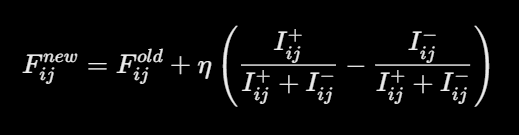

In [34]:
import numpy as np

def update_federation(F, domain_influence, learning_rate=0.1):

    for (source_domain, target_domain), influences in domain_influence.items(): #going through every domain pair

        '''
        source_domain = 0
        target_domain = 1

        influences = [0.4, 0.2, -0.1, 0.5]
        '''

        positive_influence = sum(
            x for x in influences if x > 0
        )

        negative_influence = sum(
            abs(x) for x in influences if x < 0
        )

        total_influence = positive_influence + negative_influence

        # No influence between these domains
        if total_influence == 0:
            continue

        # Fractions
        positive_fraction = positive_influence / total_influence
        negative_fraction = negative_influence / total_influence

        # Positive → increase F
        # Negative → decrease F
        net_fraction = positive_fraction - negative_fraction

        F[source_domain][target_domain] += (
            learning_rate * net_fraction
        )

        # Keep federation score between 0 and 1
        F[source_domain][target_domain] = np.clip(
            F[source_domain][target_domain],
            0,
            1
        )

    return F

creating user threshold for cross domain

In [35]:
user_threshold = {
    node: np.random.uniform(0, 1)
    for node in domains
}

Calling Diffuison main

In [36]:
threshold_for_cross_domain = 0.3

positive, negative = diffusion_model(
    graph,
    top_k_nodes,
    domains,
    threshold_for_cross_domain,
    F,
    10,
    0.1,
    user_threshold

)

 #  iterations=10,
 # learning_rate=0.1,

total = len(positive | negative)

print("Positive nodes:", len(positive))
print("Negative nodes:", len(negative))
print("Total influenced nodes:", total)

print("Positive edges:", (random_df["sign"] > 0).sum())
print("Negative edges:", (random_df["sign"] < 0).sum())

print("Positive edge percentage:",
      (random_df["sign"] > 0).mean() * 100)

print("Negative edge percentage:",
      (random_df["sign"] < 0).mean() * 100)

print("Average positive weight:",
      random_df.loc[random_df["sign"] > 0, "sign"].mean() / 10)

print("Average negative magnitude:",
      abs(random_df.loc[random_df["sign"] < 0, "sign"].mean() / 10))

print("Max positive weight:",
      random_df.loc[random_df["sign"] > 0, "sign"].max() / 10)

print("Max negative magnitude:",
      abs(random_df.loc[random_df["sign"] < 0, "sign"].min() / 10))

Positive nodes: 2474
Negative nodes: 517
Total influenced nodes: 2991
Positive edges: 32029
Negative edges: 3563
Positive edge percentage: 89.98932344347045
Negative edge percentage: 10.010676556529557
Average positive weight: 0.04997865822855991
Average negative magnitude: 0.05007771208181333
Max positive weight: 0.09999470418125021
Max negative magnitude: 0.09999694352249153
